<a href="https://colab.research.google.com/github/931661716/GenAI-for-image-and-video/blob/main/Object_detection_In_Class_2026_v3_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thực hành: Phát hiện đối tượng YOLO
Trong bài này ta sẽ thực hành bài toán phát hiện quả dừa trên băng chuyền bằng mô hình YOLO

> **Lời giải.** Notebook này chạy trên **Google Colab** (Runtime → Change runtime type → **GPU**). Các ô 💡 giải thích ý nghĩa từng bước.
>
> Pipeline tổng thể: *Tải code YOLOv3 → chuẩn bị nhãn đúng định dạng YOLO → khai báo dataset (yaml) → fine-tune → inference → tự cấu hình anchor/hyp → viết hàm `detect()` riêng.*

# 1. Cài đặt

In [ ]:
!nvidia-smi -L   # kiểm tra đã có GPU chưa

GPU 0: Tesla T4 (UUID: GPU-07b5bfa3-a316-4951-4e60-fc7a87f1681c)


Tải YOLO

💡 Repo `ultralytics/yolov3` chứa toàn bộ code: `train.py` (huấn luyện), `detect.py` (suy luận), `models/` (kiến trúc mạng dạng yaml), `data/` (cấu hình dataset + siêu tham số), `utils/` (dataloader, NMS, loss...).
Ta clone vào `/content` để các đường dẫn phía sau thống nhất.

In [ ]:
%cd /content
!git clone https://github.com/ultralytics/yolov3

/content
fatal: destination path 'yolov3' already exists and is not an empty directory.


In [ ]:
%cd /content/yolov3

/content/yolov3


Cài đặt các thư viện cần thiết sử dụng pip install requrement.txt

💡 `requirements.txt` liệt kê các thư viện cần (torch, opencv, PyYAML, ultralytics...). `-q` để log gọn hơn.

In [ ]:
!pip install -q -r requirements.txt

# 2. Gán nhãn dữ liệu  
Làm quen với gán nhãn dữ liệu bằng công cụ LabelImg
1. Cài đặt công cụ LabelImg: https://github.com/tzutalin/labelImg  
2. Chỉnh sửa predefined_classes.txt trong thư mục labelimg/data: Xoá nội dung 15 class có sẵn và thay bằng coconut  
3. Mở labelimg: python3 labelimg  
4. Chọn thư mục samples, chọn định dạng YOLO và thực hiện đánh nhãn


💡 Khi chọn định dạng **YOLO**, LabelImg lưu mỗi ảnh thành 1 file `.txt`, mỗi dòng `class x_center y_center width height` (đã chuẩn hoá về [0,1]) — đúng định dạng ta sẽ tự sinh ở phần 3. Phần này làm trên máy cá nhân (LabelImg cần giao diện đồ hoạ), không chạy trong Colab.

# 3. Chuẩn bị dữ liệu

**Mô tả**: Trong thư mục datasets chứa bộ dữ liệu sử dụng trong bài thực hành này. Trong thư mục này chứa thư mục con **images** gồm toàn bộ ảnh dữ liệu; file **all_annotations.txt** chứa nhãn bounding box của toàn bộ ảnh (được đánh nhãn sẵn từ trước). File **all_annotations.txt** gồm nhiều dòng, mỗi dòng có format như sau:

_image_path x1,y1,u1,v1,c1 x2,y2,u2,v2,c2 ... xn, yn, un, vn, cn_

Trong đó (xi, yi) là tọa độ góc trên trái của đối tượng thứ i, (ui, vi) là tọa độ góc trên phải của đối tượng thứ i, ci là lớp của đối tượng thứ i. Trong bài thực hành này ta chỉ có một lớp dữ liệu duy nhất.


**Mô tả format annotation mới**: Mỗi ảnh ta sẽ có 1 file .txt lưu thông tin các bounding box. File .txt này có định dạng như sau:

*   Mỗi bounding box một dòng trong file
*   Format của từng dòng là: class x_center y_center width height
*   Cần normalize x_center y_center width height về range [0, 1]
*   class được đánh số bắt đầu từ 0

**Công việc cần thực hiện**:  

1.   Tạo thư mục datasets/labels chứa toàn bộ các file .txt (mỗi ảnh trong thư mục datasets/images ứng với 1 file .txt trong thư mục datasets/labels) theo mô tả ở trên)
2.   Tham khảo file yolov3/data/coco.yaml, tạo file yolov3/data/coconut.yaml ứng với dataset ta vừa xử lý








💡 **Lưu ý:** thực tế `(ui, vi)` là **góc dưới phải** của box (không phải góc trên phải) — đã vẽ thử để kiểm tra. Công thức chuyển từ `(x1, y1, x2, y2)` (pixel) sang định dạng YOLO:

| Đại lượng | Công thức |
|---|---|
| x_center | (x1 + x2) / 2 / W |
| y_center | (y1 + y2) / 2 / H |
| width | (x2 − x1) / W |
| height | (y2 − y1) / H |

với W, H là chiều rộng/cao ảnh. Chuẩn hoá về [0,1] giúp nhãn không phụ thuộc kích thước ảnh (YOLO sẽ resize ảnh về 416×416 khi train).

Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

Upload datasets.zip và unzip

**Lưu ý:** Trong file zip sẵn chỉ có 20 ảnh. Nếu muốn tải full dữ liệu, các bạn có thể tải tại link sau: <a href="https://u.pcloud.link/publink/show?code=XZp1BhVZmloQdDfGGHFnNfoK7gX2vy66NlrX&fbclid=IwY2xjawFgZ1FleHRuA2FlbQIxMAABHTgHKueaW_1VSEELuOk6RSmPuJ57dld_msT0EKG2GVTOGaWah78rqHuXJg_aem_z34JWfq4mptE_3KBbeNKtw">https://u.pcloud.link/publink/show?code=XZp1BhVZmloQdDfGGHFnNfoK7gX2vy66NlrX&fbclid=IwY2xjawFgZ1FleHRuA2FlbQIxMAABHTgHKueaW_1VSEELuOk6RSmPuJ57dld_msT0EKG2GVTOGaWah78rqHuXJg_aem_z34JWfq4mptE_3KBbeNKtw</a>

💡 Cách 1: kéo-thả `datasets.zip` vào thư mục `/content` ở thanh Files bên trái. Cách 2: để file trên Drive rồi copy sang (bỏ comment dòng `cp`).

In [ ]:
%cd /content
# !cp /content/drive/MyDrive/datasets.zip /content/   # nếu datasets.zip nằm trên Drive
!ls

/content
datasets  datasets.zip	sample_data  yolov3


💡 `datasets.zip` lại chứa **2 file zip con** (`images.zip`, `labels.zip`) nên phải giải nén 2 lớp. `-x "__MACOSX/*"` bỏ rác do macOS tạo ra. Kết quả mong muốn:
```
/content/datasets/
├── all_annotations.txt
├── images/   (1.png ... 20.png)
└── labels/   (rỗng, sẽ sinh ở bước 1)
```

In [ ]:
%cd /content
!unzip -qo datasets.zip -x "__MACOSX/*"
%cd /content/datasets
!unzip -qo images.zip -x "__MACOSX/*"
!unzip -qo labels.zip -x "__MACOSX/*"
%cd /content
!ls datasets/images | head

/content
/content/datasets
/content
10.png
11.png
12.png
13.png
14.png
15.png
16.png
17.png
18.png
19.png


### Bước 1: Sinh file nhãn `.txt` cho từng ảnh
💡 Đọc từng dòng `all_annotations.txt` → lấy đường dẫn ảnh → đọc ảnh để biết W, H → đổi mỗi box sang `class xc yc w h` → ghi vào `datasets/labels/<tên ảnh>.txt`.

Sửa so với code mẫu: `os.makedir` → `os.makedirs` (hàm `makedir` không tồn tại); bỏ qua các dòng có ảnh không nằm trong bản 20 ảnh (file annotation có 402 dòng). YOLO tự tìm nhãn bằng cách thay `/images/` thành `/labels/` trong đường dẫn ảnh, nên 2 thư mục phải nằm cạnh nhau và cùng tên file.

In [ ]:
# Bước 1: Sinh file .txt chứa thông tin bounding box cho từng ảnh
import os
import cv2

IMAGE_FOLDER = 'datasets/images'
ANNOTATION_FILE = 'datasets/all_annotations.txt'
LABEL_FOLDER = 'datasets/labels'

os.makedirs(LABEL_FOLDER, exist_ok=True)

n_files = 0
with open(ANNOTATION_FILE) as f:
  for line in f:
    data = line.split()
    if not data:
      continue

    image_fp = data[0]                                           # ./datasets/images/1.png
    image_idx = os.path.splitext(os.path.basename(image_fp))[0]  # '1'
    if not os.path.exists(image_fp):                             # ảnh không có trong bản 20 ảnh
      continue
    image = cv2.imread(image_fp)
    height, width = image.shape[:2]

    normalized_bbox = []
    for bbox in data[1:]:
      x, y, u, v, cls = [int(a) for a in bbox.split(',')]       # (x,y) trên-trái, (u,v) dưới-phải
      x_center = (x + u) / 2 / width
      y_center = (y + v) / 2 / height
      box_width = (u - x) / width
      box_height = (v - y) / height
      normalized_bbox.append((cls, x_center, y_center, box_width, box_height))

    with open(os.path.join(LABEL_FOLDER, image_idx + '.txt'), 'w') as g:
      for c, xc, yc, bw, bh in normalized_bbox:
        g.write(f'{c} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n')
    n_files += 1

print('Số file nhãn đã tạo:', n_files)
print(open(os.path.join(LABEL_FOLDER, '1.txt')).read())

Số file nhãn đã tạo: 20
0 0.384722 0.476562 0.380556 0.256250
0 0.205556 0.717969 0.405556 0.220312
0 0.723611 0.539844 0.258333 0.223438
0 0.123611 0.342187 0.230556 0.193750



💡 Luôn **vẽ lại nhãn lên ảnh** để chắc chắn chuyển đổi đúng — sai nhãn thì train bao lâu cũng vô ích.

In [ ]:
import matplotlib.pyplot as plt

def show_labels(name):
  im = cv2.imread(f'datasets/images/{name}.png')
  h, w = im.shape[:2]
  for line in open(f'datasets/labels/{name}.txt'):
    c, xc, yc, bw, bh = map(float, line.split())
    p1 = (int((xc - bw / 2) * w), int((yc - bh / 2) * h))
    p2 = (int((xc + bw / 2) * w), int((yc + bh / 2) * h))
    cv2.rectangle(im, p1, p2, (0, 0, 255), 4)
  plt.figure(figsize=(5, 8)); plt.imshow(im[..., ::-1]); plt.axis('off'); plt.show()

show_labels('1')

### Bước 2: Tạo file `yolov3/data/coconut.yaml`
💡 File này cho `train.py` biết: dữ liệu ở đâu (`path`), ảnh train/val (tương đối so với `path`), số lớp `nc` và tên lớp `names`.
Vì chỉ có 20 ảnh nên dùng chung cho cả train và val (chỉ để thực hành — bài thật phải tách riêng tập val để đánh giá trung thực).
`%%writefile` ghi nội dung ô ra file (thay cho việc `cp coco.yaml` rồi sửa tay).

In [ ]:
%%writefile /content/yolov3/data/coconut.yaml
path: /content/datasets   # thư mục gốc dataset
train: images             # = /content/datasets/images
val: images

nc: 1                     # số lớp
names: ['coconut']        # class 0 = coconut

Overwriting /content/yolov3/data/coconut.yaml


# 4. Huấn luyện mô hình

💡 Tắt Weights & Biases để `train.py` không dừng lại hỏi đăng nhập (như log cũ: *wandb: Enter your choice*).

In [ ]:
%cd /content/yolov3
%env WANDB_MODE=disabled

/content/yolov3
env: WANDB_MODE=disabled


## Cách 1: Finetune

Ta sẽ thử fine-tune model với pretrained có sẵn, các tham số theo như mặc định (tham khảo file yolov3/train.py), đây là cách chúng ta luôn thử đầu tiên với một bài toán mới. Bạn có thể thay đổi số epoch để rút ngắn thời gian training. Sau khi kết thúc quá trình training, hãy nhìn vào phần log cuối cùng để xác định vị trí lưu weights đã train.

💡 Ý nghĩa tham số:
- `--img 416`: resize ảnh về 416×416 (bội số của stride 32).
- `--batch 16`: số ảnh mỗi lần cập nhật trọng số.
- `--epochs 20`: số lần duyệt hết dataset.
- `--data data/coconut.yaml`: dataset vừa khai báo.
- `--weights yolov3.pt`: **trọng số pretrained trên COCO** (tự tải về). Backbone đã biết trích đặc trưng tốt, chỉ lớp Detect (80 lớp → 1 lớp) phải học lại → hội tụ nhanh dù rất ít dữ liệu. Đó là *transfer learning / fine-tune*.
- `--name finetune --exist-ok`: lưu kết quả cố định ở `runs/train/finetune` (thay vì exp, exp2, exp3...).

Cuối log sẽ in `Results saved to runs/train/finetune`; trọng số ở `weights/best.pt` (mAP tốt nhất) và `weights/last.pt` (epoch cuối).

In [ ]:
!python train.py --img 416 --batch 16 --epochs 20 --data data/coconut.yaml --weights yolov3.pt --name finetune --exist-ok

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov3#integrations.
I0000 00:00:1791641969.810380   10294 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: batch_size=16, bbox_interval=-1, bucket=, cache=None, cfg=, cos_lr=False, data=data/coconut.yaml, device=, entity=None, epochs=20, evolve=None, exist_ok=True, freeze=[0], hyp=data/hyps/hyp.scratch-low.yaml, image_weights=False, imgsz=416, label_smoothing=0.0, local_rank=-1, multi_scale=False, name=finetune, noautoanchor=False, noplots=False, nosave=False, noval=False, optimizer=SGD, patience=100, project=runs/train, quad=False, rect=False, resume=False, save_period=-1, seed=0, single_cls=False, sync_bn=False, upload_dataset=False, weights=yolov3.pt, workers=8
github: up to date with https://github.com/ultralytics/yolov3 ✅
YOLOv3 🚀 v9.6.0-367-g97493de Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T

💡 Xem đường cong loss/precision/recall/mAP. `box_loss`, `obj_loss` giảm và `mAP_0.5` tăng là mô hình đang học tốt.

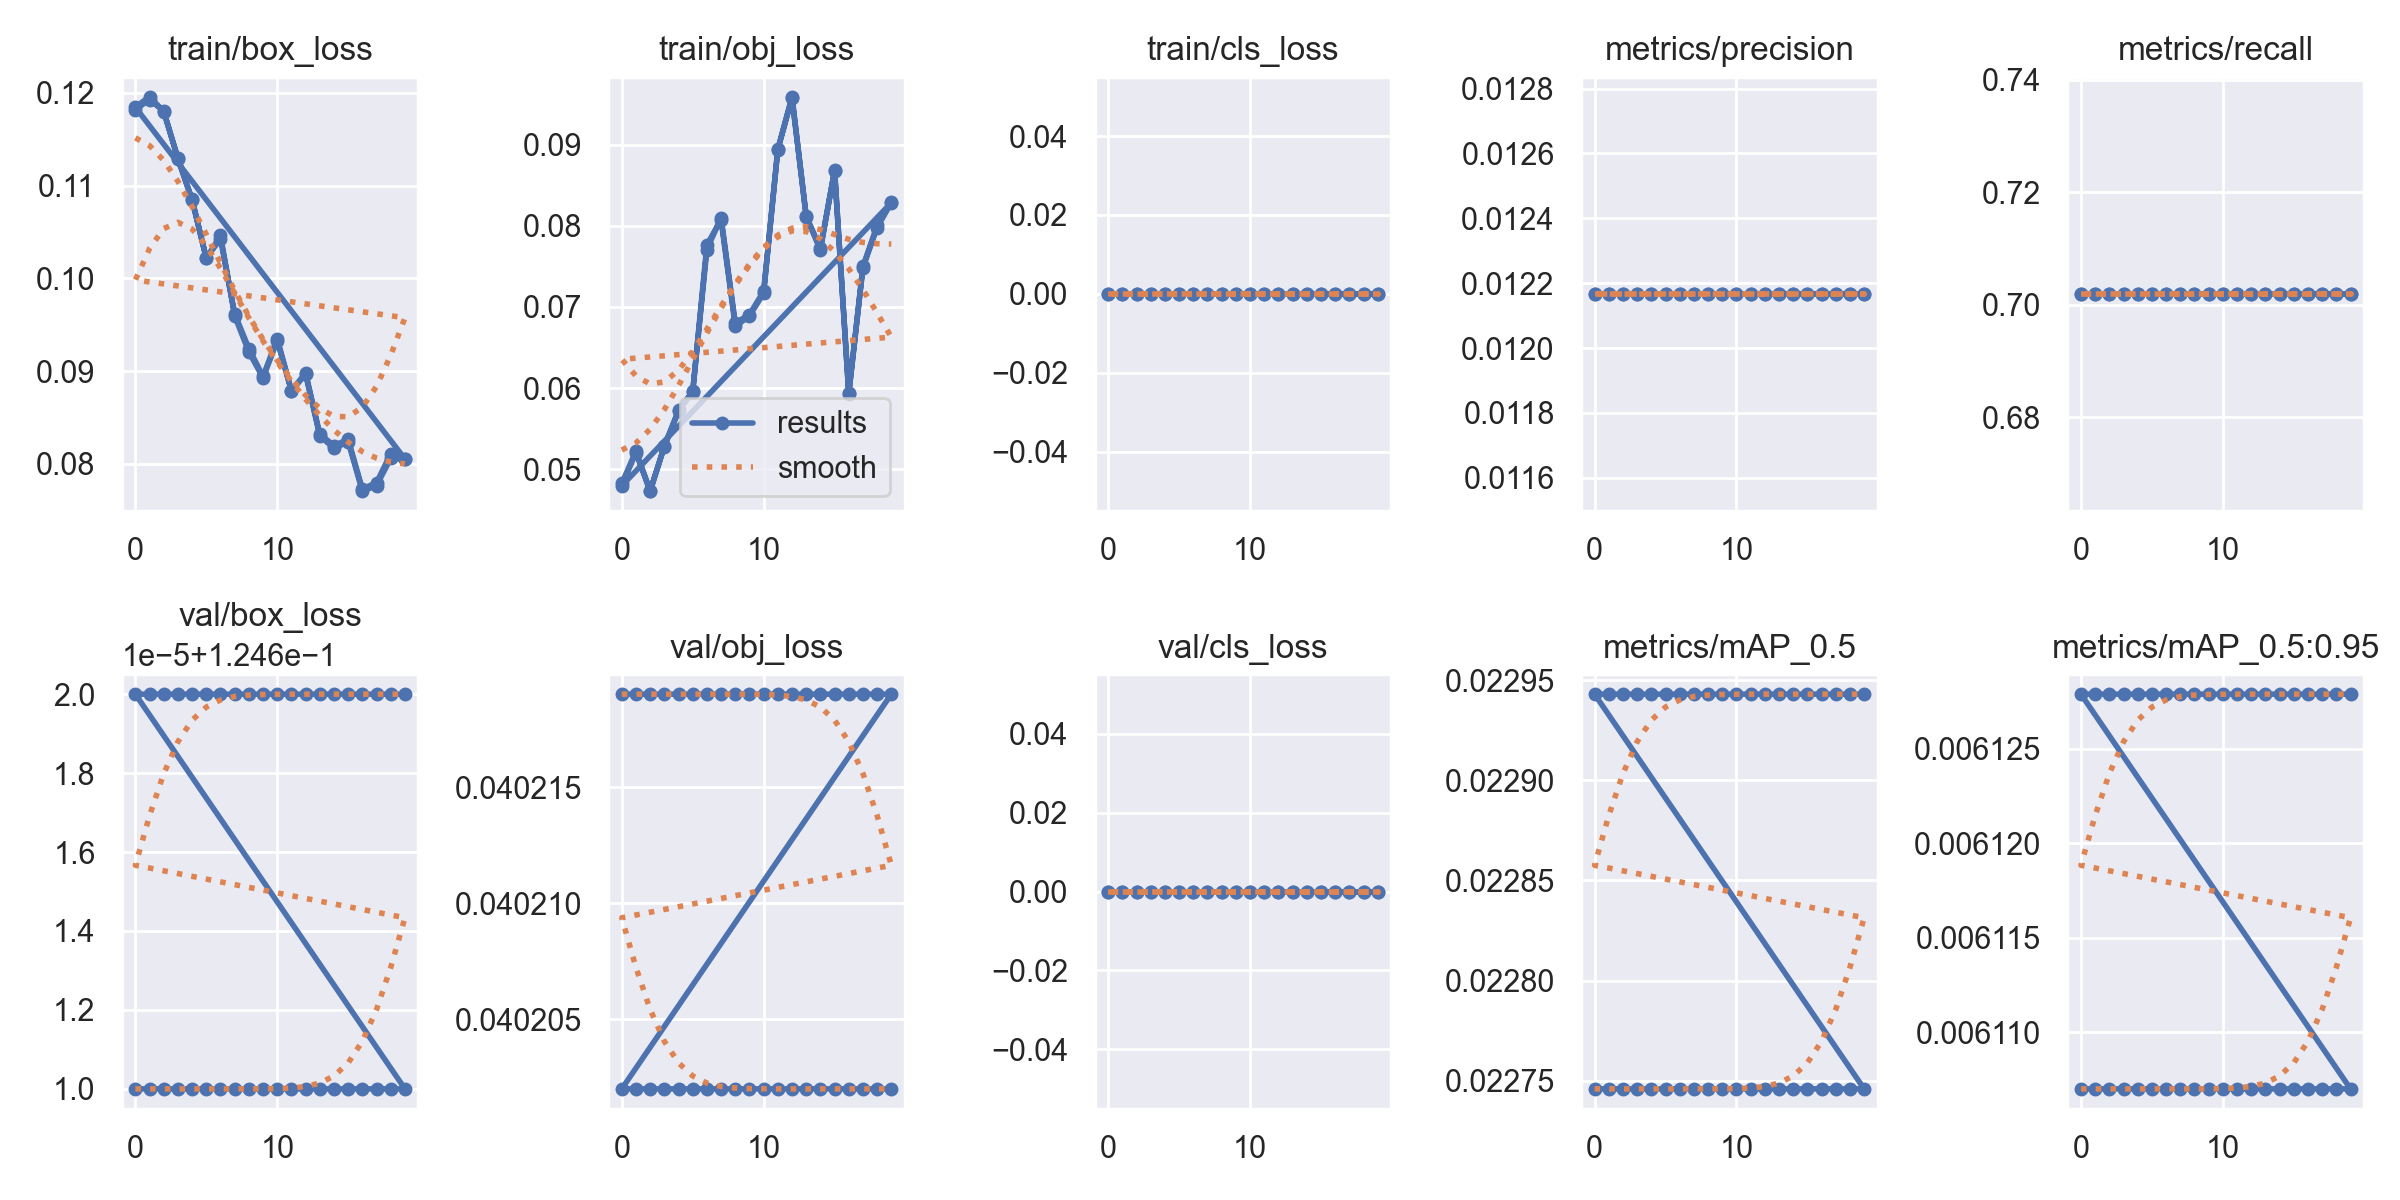

In [ ]:
from IPython.display import Image, display
display(Image('runs/train/finetune/results.png', width=900))

Thử inference trên 1 video sử dụng model đã finetune ở trên, ta sẽ sử dụng IoU threshold cho phần NMS là 0.5, threshold cho object score là 0.6  

Tải video tại link sau: ***https://u.pcloud.link/publink/show?code=XZziBhVZgRqC3dfFdWL1kB1zq0py6BbrMJny***

💡 Tải `coconut.mp4` từ link trên rồi upload vào `/content/datasets/`.
- `--conf-thres 0.6`: chỉ giữ box có độ tin cậy (objectness × class prob) ≥ 0.6.
- `--iou-thres 0.5`: trong **NMS**, các box chồng nhau có IoU > 0.5 với box có điểm cao hơn sẽ bị loại → mỗi quả dừa chỉ còn 1 box.

Video kết quả lưu ở `runs/detect/coconut_video/`. Nếu chưa có video, có thể thay `--source` bằng `/content/datasets/images` để chạy trên ảnh.

In [ ]:
!python detect.py --weights runs/train/finetune/weights/best.pt --source /content/datasets/coconut.mp4 --imgsz 416 --iou-thres 0.5 --conf-thres 0.6 --name coconut_video --exist-ok

Streaming output truncated to the last 5000 lines.
video 1/1 (1775/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 19.5ms
video 1/1 (1776/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 21.5ms
video 1/1 (1777/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 20.6ms
video 1/1 (1778/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 19.2ms
video 1/1 (1779/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 21.5ms
video 1/1 (1780/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 19.8ms
video 1/1 (1781/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 20.8ms
video 1/1 (1782/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 20.9ms
video 1/1 (1783/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 19.2ms
video 1/1 (1784/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 21.1ms
video 1/1 (1785/27017) /content/datasets/coconut.mp4: 416x256 (no detections), 20.8ms
vid

## Cách 2: Tự cấu hình lại các tham số

Để làm chủ việc training model, ta có thể tự thay đổi các tham số để phù hợp với từng bộ dữ liệu khác nhau. Bài toán coconut detection khá đơn giản, vì vậy cách sử dụng pretrained ở trên đã cho kết quả tốt, tuy nhiên với nhiều bài toán phức tạp hơn, ta sẽ cần thay đổi các tham số sao cho phù hợp. Ở đây ta sẽ cấu hình 2 phần chính:


*   Anchor boxes và Model architecture
*   Model hyper parameters








### Anchor boxes và Model architecture

- Hãy quan sát file yolov3/models/yolov3.yaml. Ta sẽ tạo file yolov3/models/coconut.yaml để tự cấu hình.
- Phần architecture gồm backbone và head bạn có thể tự thay đổi ở nhà để thử nghiệm, trong bài thực hành này ta sẽ giữ nguyên architecture của yolov3
- Tham số _nc_ là số lượng lớp của bài toán, ta cần thay đổi cho phù hợp (ở cách train 1 ở trên, ta không chỉ định file config yaml này thì model tự hiểu lấy tham số _nc_ trong file data/coconut.yaml)
- Tham số anchors: Trong nhiều bài toán phức tạp, việc tìm anchor boxes mới là cần thiết. Bạn có thể tham khảo repo sau: <a href=https://github.com/decanbay/YOLOv3-Calculate-Anchor-Boxes>https://github.com/decanbay/YOLOv3-Calculate-Anchor-Boxes </a>. Hãy thử thay đổi anchor box của mô hình như sau:

```
P3/8: 77,34, 84,50, 87,70

P4/16: 100,43, 107,59, 117,75

P5/32: 128,50, 142,66, 153,87
```



💡 YOLOv3 dự đoán ở **3 tỉ lệ**: P3 (stride 8, lưới 52×52 → vật nhỏ), P4 (stride 16, 26×26 → vật vừa), P5 (stride 32, 13×13 → vật lớn). Mỗi tỉ lệ có 3 anchor (w, h tính bằng pixel ở ảnh đầu vào 416). Mạng không đoán kích thước box từ đầu mà đoán **độ lệch so với anchor**, nên anchor càng giống kích thước vật thật thì càng dễ học.

Anchor mặc định (10×13 ... 373×326) tính cho COCO; dừa trên băng chuyền có kích thước khá đồng đều nên anchor mới chỉ trải trong khoảng 77–153 px. Ngoài anchor và `nc: 1`, kiến trúc giữ nguyên như `models/yolov3.yaml`.

Lưu ý: khi train, YOLO chạy **AutoAnchor** — nếu anchor khớp kém với nhãn (BPR < 0.98) nó sẽ tự tính lại; muốn giữ nguyên anchor của mình thì thêm cờ `--noautoanchor`.

In [ ]:
%%writefile /content/yolov3/models/coconut.yaml
# Parameters
nc: 1 # number of classes
depth_multiple: 1.0 # model depth multiple
width_multiple: 1.0 # layer channel multiple
anchors:
  - [77,34, 84,50, 87,70]       # P3/8
  - [100,43, 107,59, 117,75]    # P4/16
  - [128,50, 142,66, 153,87]    # P5/32

# darknet53 backbone
backbone:
  # [from, number, module, args]
  [
    [-1, 1, Conv, [32, 3, 1]], # 0
    [-1, 1, Conv, [64, 3, 2]], # 1-P1/2
    [-1, 1, Bottleneck, [64]],
    [-1, 1, Conv, [128, 3, 2]], # 3-P2/4
    [-1, 2, Bottleneck, [128]],
    [-1, 1, Conv, [256, 3, 2]], # 5-P3/8
    [-1, 8, Bottleneck, [256]],
    [-1, 1, Conv, [512, 3, 2]], # 7-P4/16
    [-1, 8, Bottleneck, [512]],
    [-1, 1, Conv, [1024, 3, 2]], # 9-P5/32
    [-1, 4, Bottleneck, [1024]], # 10
  ]

# YOLOv3 head
head: [
    [-1, 1, Bottleneck, [1024, False]],
    [-1, 1, Conv, [512, 1, 1]],
    [-1, 1, Conv, [1024, 3, 1]],
    [-1, 1, Conv, [512, 1, 1]],
    [-1, 1, Conv, [1024, 3, 1]], # 15 (P5/32-large)

    [-2, 1, Conv, [256, 1, 1]],
    [-1, 1, nn.Upsample, [None, 2, "nearest"]],
    [[-1, 8], 1, Concat, [1]], # cat backbone P4
    [-1, 1, Bottleneck, [512, False]],
    [-1, 1, Bottleneck, [512, False]],
    [-1, 1, Conv, [256, 1, 1]],
    [-1, 1, Conv, [512, 3, 1]], # 22 (P4/16-medium)

    [-2, 1, Conv, [128, 1, 1]],
    [-1, 1, nn.Upsample, [None, 2, "nearest"]],
    [[-1, 6], 1, Concat, [1]], # cat backbone P3
    [-1, 1, Bottleneck, [256, False]],
    [-1, 2, Bottleneck, [256, False]], # 27 (P3/8-small)

    [[27, 22, 15], 1, Detect, [nc, anchors]], # Detect(P3, P4, P5)
  ]

Overwriting /content/yolov3/models/coconut.yaml


### Model hyper parameter

Các siêu tham số cho quá trình huấn luyện mô hình được lưu ở các file yaml trong thư mục yolov3/data/hyps. Hãy quan sát file hyp.scratch.yaml và thay đổi theo ý muốn của bạn

💡 Repo hiện tại **không còn** `hyp.scratch.yaml`; thay vào đó có `hyp.scratch-low/med/high.yaml` (mức augmentation thấp/vừa/cao). Ta copy `hyp.scratch-low.yaml` thành `hyp.coconut.yaml` rồi sửa vài tham số hợp với bài toán:
- `flipud: 0.5` — camera nhìn từ trên xuống băng chuyền, dừa lật dọc vẫn là dừa → thêm augmentation hợp lý.
- `degrees: 10` — xoay nhẹ ±10°.
- `lr0: 0.005` — learning rate nhỏ hơn vì đang fine-tune từ pretrained, tránh phá hỏng trọng số tốt sẵn có.

Các nhóm tham số chính: learning rate/optimizer (`lr0, lrf, momentum, weight_decay, warmup_*`), trọng số các loss (`box, cls, obj`), ngưỡng gán anchor (`anchor_t`), và augmentation (`hsv_*, degrees, translate, scale, fliplr, flipud, mosaic, mixup`).

In [ ]:
import yaml
with open('data/hyps/hyp.scratch-low.yaml') as f:
  hyp = yaml.safe_load(f)

hyp.update({'flipud': 0.5, 'degrees': 10.0, 'lr0': 0.005})

with open('data/hyps/hyp.coconut.yaml', 'w') as f:
  yaml.safe_dump(hyp, f, sort_keys=False)
print(hyp)

{'lr0': 0.005, 'lrf': 0.01, 'momentum': 0.937, 'weight_decay': 0.0005, 'warmup_epochs': 3.0, 'warmup_momentum': 0.8, 'warmup_bias_lr': 0.1, 'box': 0.05, 'cls': 0.5, 'cls_pw': 1.0, 'obj': 1.0, 'obj_pw': 1.0, 'iou_t': 0.2, 'anchor_t': 4.0, 'fl_gamma': 0.0, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4, 'degrees': 10.0, 'translate': 0.1, 'scale': 0.5, 'shear': 0.0, 'perspective': 0.0, 'flipud': 0.5, 'fliplr': 0.5, 'mosaic': 1.0, 'mixup': 0.0, 'copy_paste': 0.0}


### Training model

💡 So với cách 1, thêm `--cfg` (kiến trúc + anchor tự định nghĩa) và `--hyp` (siêu tham số tự định nghĩa). Trọng số pretrained vẫn được nạp cho các lớp khớp shape. So sánh `results.png` / mAP của `runs/train/custom` với `runs/train/finetune`.

In [ ]:
!python train.py --img 416 --batch 16 --epochs 20 --data data/coconut.yaml --weights yolov3.pt --cfg models/coconut.yaml --hyp data/hyps/hyp.coconut.yaml --name custom --exist-ok

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov3#integrations.
I0000 00:00:1791643157.675376   15353 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: batch_size=16, bbox_interval=-1, bucket=, cache=None, cfg=models/coconut.yaml, cos_lr=False, data=data/coconut.yaml, device=, entity=None, epochs=20, evolve=None, exist_ok=True, freeze=[0], hyp=data/hyps/hyp.coconut.yaml, image_weights=False, imgsz=416, label_smoothing=0.0, local_rank=-1, multi_scale=False, name=custom, noautoanchor=False, noplots=False, nosave=False, noval=False, optimizer=SGD, patience=100, project=runs/train, quad=False, rect=False, resume=False, save_period=-1, seed=0, single_cls=False, sync_bn=False, upload_dataset=False, weights=yolov3.pt, workers=8
github: up to date with https://github.com/ultralytics/yolov3 ✅
YOLOv3 🚀 v9.6.0-367-g97493de Python-3.13.15 torch-2.11.0+cu130 CU

# 5. Làm chủ pipeline inference model đã train

Ở phần trên chúng ta sử dụng file detect.py để infer mô hình đã huấn luyện, ở phần này chúng ta sẽ dựa vào file detect.py, viết 1 hàm detector ngắn gọn, nhận vào 1 ảnh, trả lại tọa độ các bounding box của object. Việc viết hàm này sẽ giúp phần lập trình thuật toán tracking dễ dàng hơn trong các buổi sau

💡 Hàm `detect()` gom đúng các bước bên trong `detect.py`:
1. **Tiền xử lý** — `letterbox`: resize giữ tỉ lệ + padding cho chia hết stride; đổi HWC→CHW, BGR→RGB; chia 255 về [0,1].
2. **Forward** qua mạng → hàng nghìn box ứng viên.
3. **NMS** (`non_max_suppression`) — lọc theo `conf_threshold` rồi bỏ box trùng theo `iou_threshold`.
4. **`scale_boxes`** — đưa toạ độ từ ảnh letterbox về toạ độ ảnh gốc.
5. Trả về tâm, box `[x1, y1, x2, y2]` và tên lớp — tâm (centroid) sẽ dùng cho thuật toán tracking các buổi sau.

Sửa so với code mẫu: bỏ các import không còn trong repo mới (`time_sync`, `utils.plots.Annotator`), dùng GPU nếu có, bọc `torch.no_grad()`, và **khởi tạo `detector = YOLO()`** (chỗ còn trống).

In [ ]:
%cd /content/yolov3
import cv2
import torch
import numpy as np

from models.common import DetectMultiBackend
from utils.general import non_max_suppression, scale_boxes
from utils.torch_utils import select_device
from utils.augmentations import letterbox

class YOLO():
  def __init__(self, model_path='runs/train/finetune/weights/best.pt', device=''):
    self.img_size = [416, 416]
    self.model_path = model_path
    self.iou_threshold = 0.5
    self.conf_threshold = 0.3
    self.device = select_device(device)   # '' = GPU nếu có, ngược lại CPU

    # Initial model
    self.model = self.load_models()
    self.stride = self.model.stride
    self.classes = self.model.names

  def load_models(self):
    model = DetectMultiBackend(self.model_path, device=self.device)
    model.model.float()
    # Warmup: chạy thử 1 lần để khởi tạo bộ nhớ / cuDNN
    model(torch.zeros(1, 3, *self.img_size).to(self.device).type_as(next(model.model.parameters())))
    return model

  def preprocess_image(self, image):
    image = letterbox(image, self.img_size, stride=self.stride)[0]
    image = image.transpose((2, 0, 1))[::-1]  # HWC to CHW, BGR to RGB
    image = np.ascontiguousarray(image)
    return image

  @torch.no_grad()
  def detect(self, image):
    im = np.array([self.preprocess_image(image)])
    im = torch.from_numpy(im).to(self.device)
    im = im.float() / 255.0
    pred = self.model(im)
    pred = non_max_suppression(pred, self.conf_threshold, self.iou_threshold)

    original_image = image.copy()
    centers = []
    bboxes = []
    obj_type = []

    for i, det in enumerate(pred):
      det[:, :4] = scale_boxes(im.shape[2:], det[:, :4], image.shape).round()

      for *xyxy, conf, cls in reversed(det):
        xyxy = [float(a) for a in xyxy]
        bboxes.append(np.array(xyxy))

        x_center = (xyxy[0] + xyxy[2]) / 2
        y_center = (xyxy[1] + xyxy[3]) / 2
        centroid = np.array([[x_center], [y_center]])
        centers.append(np.round(centroid))

        predicted_class = self.classes[int(cls)]
        obj_type.append(predicted_class)

    return original_image, centers, bboxes, obj_type


if __name__ == "__main__":
  import matplotlib.pyplot as plt

  image = cv2.imread('../datasets/images/5.png')
  # Khởi tạo YOLO
  detector = YOLO()
  original_image, centers, bboxes, obj_type = detector.detect(image)
  print('Số quả dừa phát hiện:', len(bboxes))
  print(centers)

  # Vẽ kết quả
  vis = original_image.copy()
  for (x1, y1, x2, y2), c, name in zip(bboxes, centers, obj_type):
    cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 4)
    cv2.circle(vis, (int(c[0, 0]), int(c[1, 0])), 8, (0, 0, 255), -1)
    cv2.putText(vis, name, (int(x1), int(y1) - 10), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
  plt.figure(figsize=(5, 8)); plt.imshow(vis[..., ::-1]); plt.axis('off'); plt.show()

/content/yolov3
YOLOv3 🚀 v9.6.0-367-g97493de Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 80 layers, 61,497,430 parameters, 0 gradients, 154.5 GFLOPs
Số quả dừa phát hiện: 0
[]


In [ ]:
!zip -qr /content/runs.zip /content/yolov3/runs
from google.colab import files
files.download('/content/runs.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>